## NBA Points Predictor - XGBoost Quantile
**- Owner:** Alex

**- Status:** Exploration only

**- Last Updated:** 11/02/26

### Model

**Baseline(A):** Rolling Avg Last 10

**Model(A'):** XGBoost Quantile Model

**Model(B):** A' + Median rolling windows over mean

### Question
Does using the median over mean change which player-points sides we bet?

**Feature rule.** Both rates use prior games only, shifted like the other lags. Same-game FGA and FTA are the scoring identity. If either column includes the game being predicted, the run is void.

**Ship B in place of A' only when all three hold** on season walk-forward, then once on the untouched 2026-27 holdout. A' still has to beat the last-10 rolling points-per-minute average on q=0.50 pinball before B is compared with it.

**Metrics.** Differences are B minus A'. Negative is a gain.

| Check | Estimator | Pass |
|---|---|---|
| Median | q=0.50 pinball, paired by game date | Date-bootstrap interval entirely below 0 |
| Distribution | Mean pinball across the quantile grid, and WIS | Both ≤ 0. P(over) at the posted number uses the whole grid |
| Market | Log loss of calibrated P(over) vs the de-vigged closing line, priced games only | Interval entirely below 0, with enough priced games to read |
| Baseline | q=0.50 pinball, A' minus last-10 rolling ppm | A' is lower |


### Setup and Configurations


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import ml_insights as ml
import numpy as np
import pandas as pd

ANALYSIS_SRC = Path("src").resolve()
if not (ANALYSIS_SRC / "points_xgb").is_dir():
    ANALYSIS_SRC = Path.cwd() / "notebooks/nba/points/src"
if str(ANALYSIS_SRC) not in sys.path:
    sys.path.insert(0, str(ANALYSIS_SRC))

from points_xgb.paths import ensure_repo_on_path, repo_root

ensure_repo_on_path()

from points_xgb import (
    ARTIFACT_STEM,
    HOLDOUT_SEASON,
    ID_COLS,
    LAG_COL,
    N_BOOT,
    QUANTILES,
    ROLE_COL,
    SEED,
    TARGET_COL,
    XGB_PARAMS,
    build_miss_frame,
    build_model_frame,
    build_oos_predictions,
    calibrated_tail_frame,
    compare_to_baselines,
    data_quality,
    exploratory_metadata,
    feature_consensus,
    feature_missingness,
    feature_outlier_table,
    fold_base_knots,
    format_data_quality,
    format_rate_outliers,
    holdout_point_distribution,
    holdout_role_quantiles,
    interval_sharpness,
    load_regular_season,
    loaded_holdout_scores,
    mean_absolute_shap,
    miss_view,
    missingness_summary,
    monotone_shift,
    oof_leakage_table,
    oof_player_games,
    permutation_importance_table,
    plot_missingness,
    plot_rate,
    plot_reliability,
    plot_shap,
    positive_minutes,
    predicted_rate_tiers,
    quantile_calibration,
    quantile_crossing,
    rate_outlier_summary,
    row_pinball,
    regular_season_blocks,
    role_reading,
    rotation_team_games,
    score_predictions,
    season_coverage,
    season_missingness,
    slice_score,
    tail_calibration_rows,
    top_rate_rows,
    wis_values,
    write_oos_predictions,
)
from models.shared.analysis import analyze_correlations, run_feature_ablation
from models.shared.artifacts import load_model_bundle, save_model_bundle
from models.shared.conformal import base_knots
from models.shared.metrics import paired_date_bootstrap
from models.shared.minutes_sampler import tail_miss_rates, within_miss_rate_band
from models.shared.ppm_sampler import build_tail_tables, save_tail_sidecar
from models.shared.points_calibration import (
    calibrated_quantile_grid,
    fit_randomized_pit_map,
    pit_recalibration_payload,
    pit_walk_forward,
)
from models.shared.quantile_offsets import (
    calibration_table as jittered_calibration,
    cluster_gap_band,
    jittered_hits,
    line_band_gap,
    quantile_reliability_bins,
    reliability_pairs,
)
from models.shared.splits import (
    early_season_mask,
    prepare_splits,
    season_walk_forward_folds,
)
from models.shared.train import evaluate_holdout, run_walk_forward

ROOT = repo_root()
pd.set_option("display.max_columns", None)

print(f"Holdout season: {HOLDOUT_SEASON}")
print(f"Quantiles: {QUANTILES}")

Holdout season: 2026-27
Quantiles: [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]


### Data


In [2]:
df = load_regular_season(ROOT)
print(format_data_quality(data_quality(df), include_rate=False))
df.sample(5)

Number of rows : 179151
Number of columns: 190
Number of Unique Players: 1225
Number of Unique Games: 8396
Total number of duplicates: 0
Missing points: 0
Missing minutes: 0
Zero-minute rows: 13
Median points: 9.0
Mean points: 10.621
Max points: 83.000


,season_year,player_id,player_name,nickname,team_id,team_abbreviation,team_name,game_id,game_date,matchup,wl,min,fgm,fga,fg_pct,fg3_m,fg3_a,fg3_pct,ftm,fta,ft_pct,oreb,dreb,reb,ast,tov,stl,blk,blka,pf,pfd,pts,plus_minus,nba_fantasy_pts,dd2,td3,wnba_fantasy_pts,fp_high_score,available_flag,min_sec,team_count,e_off_rating,off_rating,sp_work_off_rating,e_def_rating,def_rating,sp_work_def_rating,e_net_rating,net_rating,sp_work_net_rating,ast_pct,ast_to,ast_ratio,oreb_pct,dreb_pct,reb_pct,tm_tov_pct,e_tov_pct,efg_pct,ts_pct,usg_pct,e_usg_pct,e_pace,pace,pace_per40,sp_work_pace,pie,poss,fgm_pg,fga_pg,team_city,team_tricode,team_slug,first_name,family_name,name_i,player_slug,start_position,comment,jersey_num,minutes,spd,dist,orbc,drbc,rbc,tchs,sast,ftast,pass,assists,cfgm,cfga,cfg_pct,ufgm,ufga,uncontested_field_goals_percentage,field_goal_percentage,dfgm,dfga,dfg_pct,team_fgm,team_fga,team_fg_pct,team_fg3_m,team_fg3_a,team_fg3_pct,team_ftm,team_fta,team_ft_pct,team_oreb,team_dreb,team_reb,team_ast,team_tov,team_stl,team_blk,team_blka,team_pf,team_pfd,team_pts,team_plus_minus,team_e_off_rating,team_off_rating,team_e_def_rating,team_def_rating,team_e_net_rating,team_net_rating,team_ast_pct,team_ast_to,team_ast_ratio,team_oreb_pct,team_dreb_pct,team_reb_pct,team_tm_tov_pct,team_efg_pct,team_ts_pct,team_e_pace,team_pace,team_pace_per40,team_poss,team_pie,opp_team_id,opp_fgm,opp_fga,opp_fg_pct,opp_fg3_m,opp_fg3_a,opp_fg3_pct,opp_ftm,opp_fta,opp_ft_pct,opp_oreb,opp_dreb,opp_reb,opp_ast,opp_tov,opp_stl,opp_blk,opp_blka,opp_pf,opp_pfd,opp_pts,opp_plus_minus,opp_e_off_rating,opp_off_rating,opp_e_def_rating,opp_def_rating,opp_e_net_rating,opp_net_rating,opp_ast_pct,opp_ast_to,opp_ast_ratio,opp_oreb_pct,opp_dreb_pct,opp_reb_pct,opp_tm_tov_pct,opp_efg_pct,opp_ts_pct,opp_e_pace,opp_pace,opp_pace_per40,opp_poss,opp_pie,season_type,pos,game_total,team_spread,player_team_spread,starting
131832,2024-25,1629667,Jalen McDaniels,Jalen,1610612764,WAS,Washington Wizards,0022400824,2025-02-24T00:00:00,WAS vs. BKN,W,0.391667,0,0,0.000,0,0,0.000,0,0,0.000,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0,0,0.0,0.0,1,0:24,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.00,0.0,0.000,0.000,0.000,0.0,0.0,0.000,0.000,0.000,0.000,122.55,122.55,102.13,122.55,0.000,1,0.0,0.0,Washington,WAS,wizards,Jalen,McDaniels,J. McDaniels,jalen-mcdaniels,,,2,0.391667,0.00,0.00,0,1,1,0,0,0,0,0,0,0,0.000,0,0,0.000,0.000,0,0,0.0,35,70,0.500,13,31,0.419,24,25,0.960,7,30,37,26,24.0,7,8,4,26,28,107,8.0,109.2,112.6,102.5,103.1,6.7,9.5,0.743,1.08,19.7,0.314,0.566,0.466,0.253,0.593,0.660,97.3,95.50,79.58,95,0.563,1610612751,33,84,0.393,14,36,0.389,19,24,0.792,16,23,39,25,18.0,16,4,8,28,26,99,-8.0,102.5,103.1,109.2,112.6,-6.7,-9.5,0.758,1.39,17.4,0.434,0.686,0.534,0.188,0.476,0.523,97.3,95.50,79.58,96,0.437,Regular Season,SF,218.0,2.5,2.5,0
146356,2024-25,1628398,Kyle Kuzma,Kyle,1610612764,WAS,Washington Wizards,0022400224,2024-11-13T00:00:00,WAS @ SAS,L,25.300000,4,9,0.444,2,6,0.333,0,0,0.000,1,5,6,2,6,0,1,1,4,0,10,-21,17.2,0,0,22.0,23.0,1,25:18,1,109.0,107.0,107.0,144.4,143.9,143.9,-35.4,-36.8,-36.8,0.111,0.33,11.8,0.050,0.227,0.143,35.3,35.3,0.556,0.556,0.242,0.246,106.97,108.14,90.12,108.14,0.023,57,4.0,9.0,Washington,WAS,wizards,Kyle,Kuzma,K. Kuzma,kyle-kuzma,F,,33,25.300000,4.28,1.93,1,9,10,38,1,0,24,2,1,1,1.000,3,8,0.375,0.444,1,1,1.0,49,95,0.516,18,44,0.409,14,16,0.875,11,30,41,27,18.0,5,5,7,23,15,130,-9.0,119.2,122.6,129.8,128.7,-10.6,-6.1,0.551,1.50,18.4,0.298,0.733,0.511,0.170,0.611,0.637,108.1,107.00,89.17,106,0.429,1610612759,48,92,0.522,18,44,0.409,25,32,0.781,8,31,39,38,9.0,7,7,5,15,23,139,9.0,129.8,128.7,119.2,122.6,10.6,6.1,0.792,4.22,24.5,0.267,0.702,0.489,0.083,0.620,0.655,108.1,107.00,89.17,108,0.571,Regular Season,PF,224.5,-9.5,9.5,1
147744,2024-25,1629008,Michael Porter Jr.,Michael,1610612743,DEN,Denver Nuggets,0022400166,2024-11-04T00:00:00,DEN vs. TOR,W,36.250000,7,16,0.438,3,10,0.300,2,3,0.667,4,5,9,3,2,1,1,0,2,1,19,1,38.3,0,0,38.0,40.0,1,36:15,1,117.6,119.5,119.5,111.8,118.2,118.2,5.

### Features


In [3]:
df = build_model_frame(df)
df.sample(5)

/Users/alexgonzalez/Documents/nba_quant/src/features/points/scoring.py:211: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  result[f"{name}_max_10"] = prior_roll(
/Users/alexgonzalez/Documents/nba_quant/src/features/points/scoring.py:204: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  result[f"{name}_min_10"] = prior_roll(
/Users/alexgonzalez/Documents/nba_quant/src/features/points/scoring.py:211: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor per

,season_year,player_id,player_name,nickname,team_id,team_abbreviation,team_name,game_id,game_date,matchup,wl,min,fgm,fga,fg_pct,fg3_m,fg3_a,fg3_pct,ftm,fta,ft_pct,oreb,dreb,reb,ast,tov,stl,blk,blka,pf,pfd,pts,plus_minus,nba_fantasy_pts,dd2,td3,wnba_fantasy_pts,fp_high_score,available_flag,min_sec,team_count,e_off_rating,off_rating,sp_work_off_rating,e_def_rating,def_rating,sp_work_def_rating,e_net_rating,net_rating,sp_work_net_rating,ast_pct,ast_to,ast_ratio,oreb_pct,dreb_pct,reb_pct,tm_tov_pct,e_tov_pct,efg_pct,ts_pct,usg_pct,e_usg_pct,e_pace,pace,pace_per40,sp_work_pace,pie,poss,fgm_pg,fga_pg,team_city,team_tricode,team_slug,first_name,family_name,name_i,player_slug,start_position,comment,jersey_num,minutes,spd,dist,orbc,drbc,rbc,tchs,sast,ftast,pass,assists,cfgm,cfga,cfg_pct,ufgm,ufga,uncontested_field_goals_percentage,field_goal_percentage,dfgm,dfga,dfg_pct,team_fgm,team_fga,team_fg_pct,team_fg3_m,team_fg3_a,team_fg3_pct,team_ftm,team_fta,team_ft_pct,team_oreb,team_dreb,team_reb,team_ast,team_tov,team_stl,team_blk,team_blka,team_pf,team_pfd,team_pts,team_plus_minus,team_e_off_rating,team_off_rating,team_e_def_rating,team_def_rating,team_e_net_rating,team_net_rating,team_ast_pct,team_ast_to,team_ast_ratio,team_oreb_pct,team_dreb_pct,team_reb_pct,team_tm_tov_pct,team_efg_pct,team_ts_pct,team_e_pace,team_pace,team_pace_per40,team_poss,team_pie,opp_team_id,opp_fgm,opp_fga,opp_fg_pct,opp_fg3_m,opp_fg3_a,opp_fg3_pct,opp_ftm,opp_fta,opp_ft_pct,opp_oreb,opp_dreb,opp_reb,opp_ast,opp_tov,opp_stl,opp_blk,opp_blka,opp_pf,opp_pfd,opp_pts,opp_plus_minus,opp_e_off_rating,opp_off_rating,opp_e_def_rating,opp_def_rating,opp_e_net_rating,opp_net_rating,opp_ast_pct,opp_ast_to,opp_ast_ratio,opp_oreb_pct,opp_dreb_pct,opp_reb_pct,opp_tm_tov_pct,opp_efg_pct,opp_ts_pct,opp_e_pace,opp_pace,opp_pace_per40,opp_poss,opp_pie,season_type,pos,game_total,team_spread,player_team_spread,starting,main_starters_playing,main_starters_defined,starter_min_missing,is_main_starter,min_avg_lN,starter_rank,starter_min_missing_teammates,main_starters_out,target_minutes,min_lag_1,min_mean_3,min_mean_5,min_mean_10,min_mean_20,min_std_10,min_vol_10,min_ewm_hl_3,min_ewm_hl_5,min_ewm_hl_10,min_ewm_hl_20,min_ge_30_rate_10,start_rate_10,min_p20_10,min_p80_10,min_p80_minus_p20_10,min_trim_mean_20,min_floor_10,min_ceiling_10,min_span_10,min_lag_outside_10,season_rows_prior,season_appearances_prior,season_min_mean,season_min_std,season_min_vol,min_unstable,season_start_rate,current_team_rows_prior,current_team_min_mean,prior_season_min_mean,prior_season_appearances,usg_wmean_10,usg_5_minus_season,touches_per_min_10,passes_per_min_10,fga_per_min_10,activity_per_min_10,assists_per_min_10,fouls_per_36_10,min_mean_vs_opp,games_vs_opp,team_pace_mean_10,team_net_rating_mean_10,team_net_rating_season,team_days_since_prev_game,is_back_to_back,team_games_prev_3d,team_games_prev_5d,opp_pace_mean_10,opp_net_rating_mean_10,expected_possessions,player_days_since_appearance,player_appearances_prev_7d,is_home,season_type_cat,team_spread_canonical,abs_spread,implied_team_total,market_missing,min_mean_3_minus_10,min_mean_10_minus_season,start_rate_x_abs_spread,min10_x_expected_possessions,pts_lag_1,pts_mean_3,pts_mean_10,pts_mean_20,pts_median_10,pts_ewm_hl_3,pts_std_10,active_pts_mean_10,season_pts_mean,two_pa,two_pm,fga_lag_1,pts_ewm_hl_5,fga_ewm_hl_5,fta_ewm_hl_5,fg3a_ewm_hl_5,two_pa_ewm_hl_5,poss_ewm_hl_5,tchs_ewm_hl_5,pfd_ewm_hl_5,cfga_ewm_hl_5,ufga_ewm_hl_5,pts_ewm_hl_10,fga_ewm_hl_10,fta_ewm_hl_10,fg3a_ewm_hl_10,two_pa_ewm_hl_10,poss_ewm_hl_10,tchs_ewm_hl_10,pfd_ewm_hl_10,cfga_ewm_hl_10,ufga_ewm_hl_10,pts_ewm_hl_20,fga_ewm_hl_20,fta_ewm_hl_20,fg3a_ewm_hl_20,two_pa_ewm_hl_20,poss_ewm_hl_20,tchs_ewm_hl_20,pfd_ewm_hl_20,cfga_ewm_hl_20,ufga_ewm_hl_20,pts_rolling_5,pts_rolling_10,pts_rolling_20,pts_rolling_3,fga_rolling_5,fga_rolling_10,fga_rolling_20,fga_rolling_3,fta_rolling_5,fta_rolling_10,fta_rolling_20,fta_rolling_3,fg3a_rolling_5,fg3a_rolling_10,fg3a_rolling_20,fg3a_rolling_3,two_pa_r

In [4]:
PTS_FEATURES = [
    # point context
    "pts_median_10",
    "pts_std_10",
    "pts_lag_1",
    "pts_trend",
    "pts_rank_10",

    # how they score
    "two_pa_median_10",
    "two_pct_smoothed",

    "fg3a_median_10",
    "three_pct_smoothed",

    "fta_median_10",
    "ft_pct_smoothed",

    # minutes context
    "min_median_10",
    "min_median_3_minus_10",
    "min_rank_10",
    "min_sd_10",

    # efficiency context
    "ts_x_usg",
    "usg_median_10",
    "usg_trend",
    "usg_rank_10",

    # game context
    "starting",
    "starter_rank",
    "start_rate_10",

    "opp_def_rating_median_10",
    "expected_pace_median",
    "implied_team_total",
    "player_team_spread",
]

### Feature Ideas

- domain measurements
- historical behavior 
- window summaries
- change and trend
- rate and ratios
- context

In [5]:
# PTS_FEATURES = [
#     "fga_rank_10",
#     "starting",
#     "fta_rolling_20",
#     "ts_x_usg",
#     "start_rate_10",
#     "fg3a_rolling_20",
#     "min_lag_1",
#     "cfga_rolling_10",
#     "cfga_rolling_5",
#     "minutes_rolling_10",
#     "ufga_rolling_5",
#     "opp_def_rating_mean_10",
#     "starter_rank",
#     "usg_rolling_10",
#     "team_games_prev_5d",
#     "fg3a_rolling_5",
#     "expected_pace",
#     "cfga_mean_3_minus_10",
#     "tchs_rolling_5",
#     "player_team_spread",
#     "min_sd_10",
#     "implied_team_total",
#     "usg_rank_10",
#     "tchs_max_10",
# ]
# print(f"size of PTS_FEATURES: {len(PTS_FEATURES)}")


### Train/validation/test design


In [6]:
from models.shared.conformal_report import ConformalSpec

TARGET_COL = "pts"
LAG_COL = "pts_lag_1"
# Cuts on predicted points q50. The rate cuts (0.30 / 0.50 / 0.70)
# would put almost every points prediction in one bin.
POINTS_SPEC = ConformalSpec(
    target_col=TARGET_COL,
    lag_col=LAG_COL,
    tiers=(
        ("<8", None, 8.0),
        ("8-15", 8.0, 15.0),
        ("15-25", 15.0, 25.0),
        ("25+", 25.0, None),
    ),
    clip_low=0.0,
    clip_high=100.0,
)


def _points_tier_mask(low, high):
    def mask(values):
        array = np.asarray(values)
        chosen = np.ones(array.shape[0], dtype=bool)
        if low is not None:
            chosen &= array >= low
        if high is not None:
            chosen &= array < high
        return chosen

    return mask


POINT_TIERS = {
    name: _points_tier_mask(low, high) for name, low, high in POINTS_SPEC.tiers
}

In [7]:
df = positive_minutes(df)
df = df.sort_values(
    ["game_date", "game_id", "player_id"], kind="mergesort"
).reset_index(drop=True)
print(f"After filtering appearances: {len(df):,} rows")
print(df[TARGET_COL].describe().round(3))

splits = prepare_splits(
    df,
    holdout_season=HOLDOUT_SEASON,
    features=PTS_FEATURES,
    target_col=TARGET_COL,
    id_cols=ID_COLS,
    role_col=ROLE_COL,
    extra_keep=[
        "minutes",
        "pts",
        "pts_lag_1",
        "season_pts_mean",
        "pts_median_10",
        "team_id",
        "season_type",
    ],
)
ppm_df = splits["ppm_df"]
ppm_holdout = splits["ppm_holdout"]
print(f"Train pool (excl. {HOLDOUT_SEASON}) : {len(ppm_df):,} rows")
print(f"Holdout   ({HOLDOUT_SEASON})        : {len(ppm_holdout):,} rows")
print(
    f"Train pool keeps every appearance, including the tails: {len(ppm_df):,} rows"
)

X = ppm_df[splits["features"]].copy()
y = ppm_df[TARGET_COL]


After filtering appearances: 179,123 rows
count    179123.000
mean         10.623
std           8.757
min           0.000
25%           4.000
50%           9.000
75%          16.000
max          83.000
Name: pts, dtype: float64
Train pool (excl. 2026-27) : 176,710 rows
Holdout   (2026-27)        : 2,413 rows
Date range (train)   : 2019-10-22 → 2026-04-12
Date range (holdout) : 2026-10-20 → 2026-11-02
Train pool (excl. 2026-27) : 176,710 rows
Holdout   (2026-27)        : 2,413 rows
Train pool keeps every appearance, including the tails: 176,710 rows


### EDA


Appearance rows: 179,123
Features with a null: 24 / 26
Rows with any null feature: 15,727 (8.8%)


,n_missing,pct_missing
three_pct_smoothed,5211,2.91
implied_team_total,5040,2.81
player_team_spread,4531,2.53
pts_trend,4382,2.45
usg_trend,4382,2.45
ft_pct_smoothed,4221,2.36
pts_std_10,2419,1.35
min_sd_10,2419,1.35
two_pct_smoothed,1900,1.06
ts_x_usg,1462,0.82


,three_pct_smoothed,implied_team_total,player_team_spread,pts_trend,usg_trend,ft_pct_smoothed,pts_std_10,min_sd_10,two_pct_smoothed,ts_x_usg,pts_mean_10,pts_lag_1,pts_rank_10,two_pa_rolling_10,fg3a_rolling_10,fta_rolling_10,min_mean_10,min_mean_3_minus_10,min_rank_10,usg_rolling_10,usg_rank_10,start_rate_10,expected_pace,opp_def_rating_mean_10
season_year,,,,,,,,,,,,,,,,,,,,,,,,
2019-20,8.0,7.7,7.7,2.4,2.4,6.2,4.7,4.7,3.2,2.7,2.4,2.4,2.4,2.4,2.4,2.4,2.4,2.4,2.4,2.4,2.4,2.4,1.5,1.4
2020-21,3.2,0.0,0.0,2.3,2.3,1.9,0.9,0.9,0.8,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.0,0.0
2021-22,2.6,4.1,2.3,2.3,2.3,2.1,1.0,1.0,0.9,0.7,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.0,0.0
2022-23,1.8,0.7,0.7,2.1,2.1,1.4,0.7,0.7,0.6,0.4,0.3,0.3,0.3,0.3,0.3,0.3,0.3,0.3,0.3,0.3,0.3,0.3,0.0,0.0
2023-24,1.8,3.9,3.9,2.2,2.2,1.8,0.8,0.8,0.7,0.5,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.0,0.0
2024-25,1.7,0.2,0.2,2.2,2.2,1.8,0.8,0.8,0.7,0.5,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.0,0.0
2025-26,1.8,2.4,2.3,2.2,2.2,1.6,0.8,0.8,0.7,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.0,0.0
2026-27,5.2,13.8,13.8,18.6,18.6,5.1,4.1,4.1,3.1,2.6,2.2,2.2,2.2,2.2,2.2,2.2,2.2,2.2,2.2,2.2,2.2,2.2,0.0,0.0


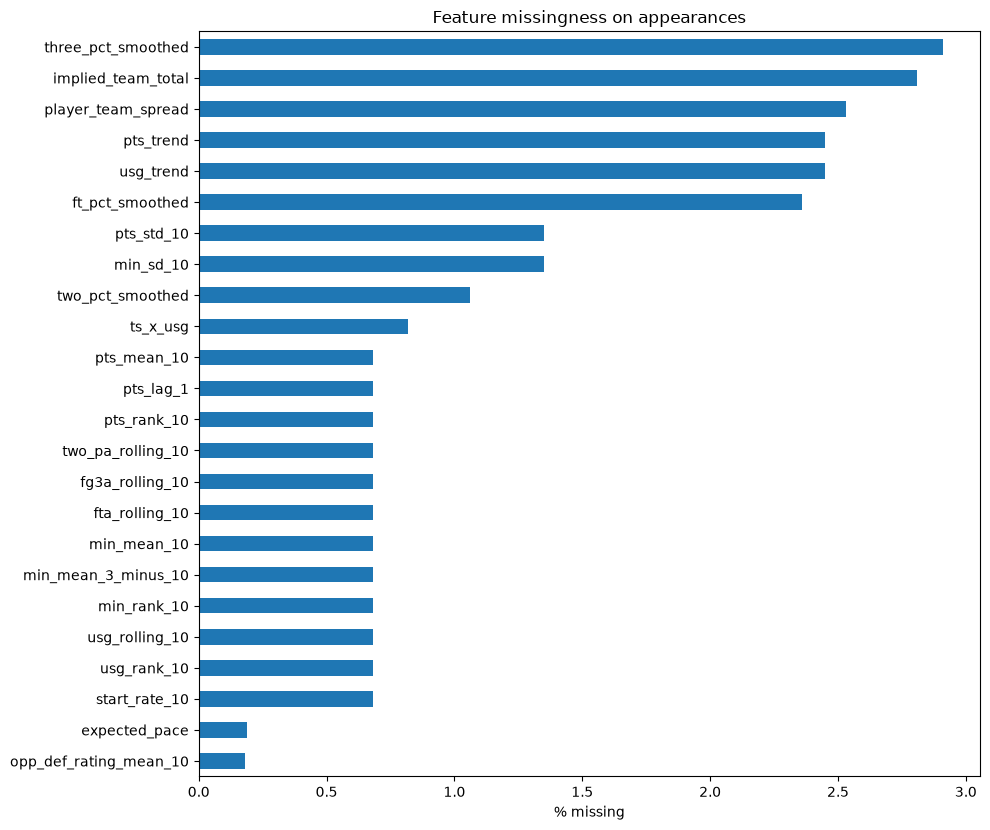

In [8]:
miss = feature_missingness(df, PTS_FEATURES)
print(missingness_summary(df, PTS_FEATURES))
display(miss)
season_miss = season_missingness(df, miss)
if not season_miss.empty:
    display(season_miss.round(3))
plot_missingness(miss)
plt.show()


n=179,123  min=0.00  p50=9.00  max=83.00
Tukey fence [-14.00, 34.00]  outside=2,632 (1.5%)


,season_year,game_date,player_name,pts,starting
171013,2025-26,2026-03-10,Bam Adebayo,83,1
111621,2023-24,2024-01-26,Luka Dončić,73,1
83230,2022-23,2023-01-02,Donovan Mitchell,71,1
90779,2022-23,2023-02-26,Damian Lillard,71,1
111054,2023-24,2024-01-22,Joel Embiid,70,1
104744,2023-24,2023-12-13,Giannis Antetokounmpo,64,1
24381,2020-21,2021-01-03,Stephen Curry,62,1
111095,2023-24,2024-01-22,Karl-Anthony Towns,62,1


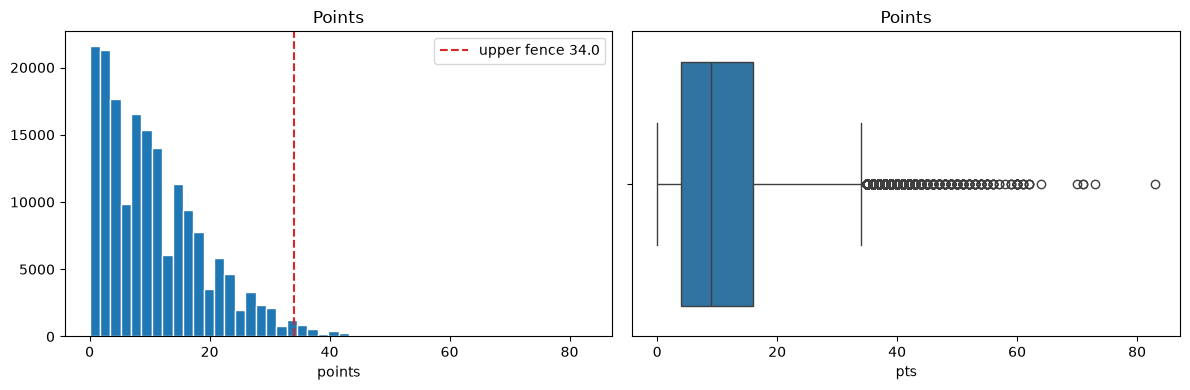

,feature,n,pct_outside,fence_low,fence_high,min,p50,max
0,three_pct_smoothed,173912,10.39,0.14,0.54,0.00,0.35,1.00
1,fta_rolling_10,177898,5.92,-2.32,5.88,0.00,1.50,16.60
2,two_pct_smoothed,177223,4.38,0.32,0.75,0.00,0.53,1.00
3,min_mean_3_minus_10,177898,3.53,-8.26,8.30,-23.00,0.00,24.58
4,usg_trend,174741,3.49,-0.08,0.08,-0.52,0.00,0.41
5,pts_trend,174741,3.41,-7.52,8.13,-23.33,0.04,34.29
6,ft_pct_smoothed,174902,2.54,0.47,1.08,0.00,0.78,1.00
7,two_pa_rolling_10,177898,2.14,-5.00,14.20,0.00,4.10,25.60
8,ts_x_usg,177661,2.06,0.01,0.20,0.00,0.10,0.50
9,min_sd_10,176704,1.92,-0.23,11.23,0.00,5.33,28.39


In [9]:
outlier_stats = rate_outlier_summary(df, TARGET_COL, unit="points")
print(format_rate_outliers(outlier_stats))
display(top_rate_rows(df, TARGET_COL))
plot_rate(df, TARGET_COL, outlier_stats["fence_high"], unit="points")
plt.show()
display(feature_outlier_table(df, PTS_FEATURES))


In [10]:
coverage = season_coverage(df, PTS_FEATURES)
display(coverage)

,rows,players,games,first_game,last_game,pct_rows_complete,mean_missing_features
season_year,,,,,,,
2019-20,22387,529,1059,2019-10-22,2020-08-14,81.0,0.81
2020-21,23053,540,1080,2020-12-22,2021-05-16,93.6,0.18
2021-22,26035,605,1230,2021-10-19,2022-04-10,90.5,0.26
2022-23,25892,539,1230,2022-10-18,2023-04-09,94.9,0.15
2023-24,26393,572,1230,2023-10-24,2024-04-14,91.5,0.23
2024-25,26302,569,1230,2024-10-22,2025-04-13,95.2,0.16
2025-26,26648,582,1230,2025-10-21,2026-04-12,93.2,0.20
2026-27,2413,448,107,2026-10-20,2026-11-02,63.4,1.15


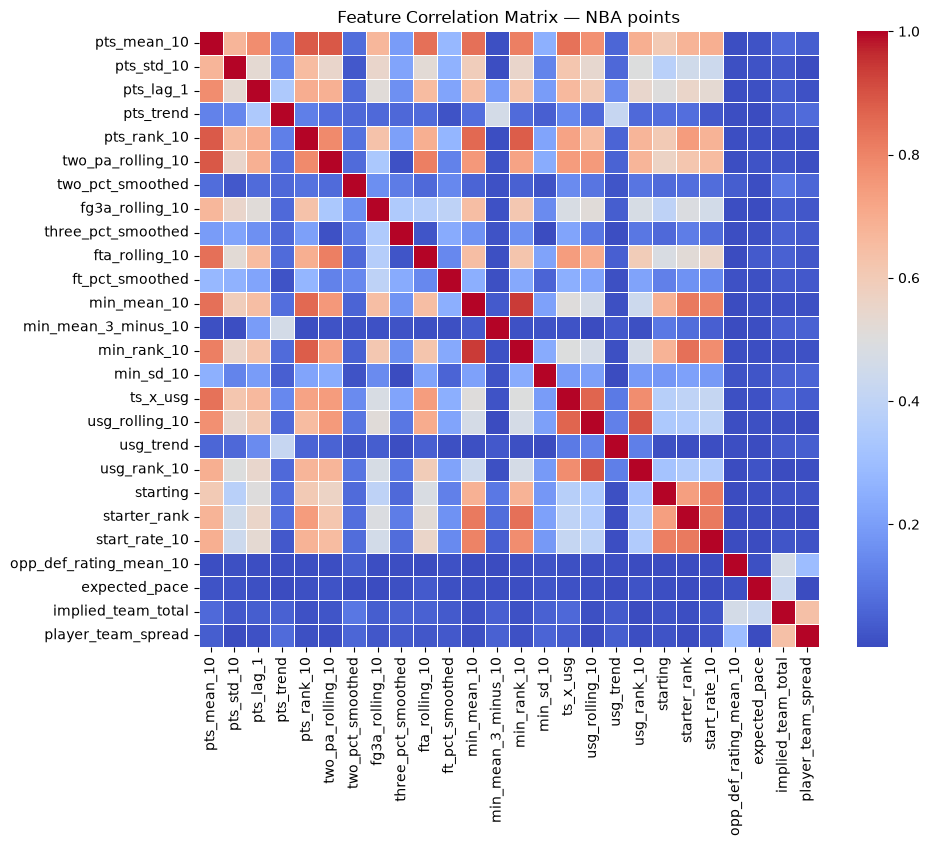

--- High Correlation Report (Threshold > 0.95) ---
No features exceed the correlation threshold.


[]

In [11]:
correlated_features = analyze_correlations(
    df, PTS_FEATURES, title="Feature Correlation Matrix — NBA points"
)
correlated_features


### Models


`XGB_PARAMS` comes from the saved dict in `points_xgb.config`. This notebook does not retune it.


In [12]:
# Hyperparameter tuning
# Leave commented if you don't want to retune the model

# import importlib
# import models.shared.train as train

# importlib.reload(train)
# tune_xgb_quantile = train.tune_xgb_quantile

# result = tune_xgb_quantile(X, y, n_trials=50, n_splits=3)
# XGB_PARAMS = result["best_params"]

#Best params: {'n_estimators': 1651, 'max_depth': 5, 'learning_rate': 0.05146292410167199, 'subsample': 0.7518573938647881, 'colsample_bytree': 0.5016248416388132, 
# 'reg_alpha': 4.492023730550085, 'reg_lambda': 0.5561894287530206, 'min_child_weight': 6}

In [13]:
VAL_SEASONS = ("2022-23", "2023-24", "2024-25", "2025-26")
season_folds = list(
    season_walk_forward_folds(
        ppm_df,
        season_col="season_year",
        val_seasons=VAL_SEASONS,
        season_type_col="season_type",
    )
)
for fold in season_folds:
    print(
        f"{fold['label']}: train {int(fold['train_mask'].sum()):,}  "
        f"val {int(fold['val_mask'].sum()):,}  "
        f"postseason left out of val {int(fold['n_val_postseason']):,}"
    )

wf = run_walk_forward(
    X, y, ppm_df,
    xgb_params=XGB_PARAMS,
    role_col=ROLE_COL,
    tiers=POINT_TIERS,
    quantiles=QUANTILES,
    folds=season_folds,
    early_team_games=10,
    target_col=TARGET_COL,
)

wf_results = wf["wf_results"]
models_last = wf["models_last"]
preds_last = wf["preds_last"]
X_val_last = wf["X_val_last"]
y_val_last = wf["y_val_last"]
starting_last = wf["starting_last"]
last_fold = wf["last_fold"]


2019-20..2021-22 -> 2022-23: train 71,475  val 25,892  postseason left out of val 0
2019-20..2022-23 -> 2023-24: train 97,367  val 26,393  postseason left out of val 0
2019-20..2023-24 -> 2024-25: train 123,760  val 26,302  postseason left out of val 0
2019-20..2024-25 -> 2025-26: train 150,062  val 26,648  postseason left out of val 0

── Phase 2: Walk-Forward Validation (XGBoost) ─────────────────
Supplied folds            : 4
  Non-regular rows excluded from the stopping tail: 0

2019-20..2021-22 -> 2022-23
  n=25892
  pinball  | q0.05=0.462  q0.10=0.831  q0.20=1.419  q0.30=1.841  q0.40=2.115  q0.50=2.250  q0.60=2.244  q0.70=2.084  q0.80=1.739  q0.90=1.143  q0.95=0.700
  mean pinball | 1.530
  coverage | 80%=80.0% (target 80%)  90%=90.2% (target 90%)
  Starters   | n=12300 | pinball q50: 2.683 | 80% coverage: 78.2%
  Bench      | n=13592 | pinball q50: 1.858 | 80% coverage: 81.6%
  minute tiers by predicted q50
  <8         | n=11997 | pinball q50: 1.718 | 80% coverage: 81.9%
  8-15

### Calibration

Walk-forward out-of-fold rows only. The 2026-27 holdout is not in this cell. The coverage table is the raw quantile model, on jittered points, so a quantile that lands on an integer is not counted as covering that integer. The early table reuses that jitter. Calibration is one map for the whole CDF. For each out-of-fold row, `u = (F(y−1) + F(y)) / 2`, the midpoint of the integer atom. Isotonic regression of the empirical CDF of `u` on `u` is the map `R`. For a line `L`, `P(over L) = 1 − R(F(L))`. `R` is fit on earlier folds and the next fold is scored with the quantiles of that recalibrated CDF. The headline on that score is mean pinball.

The noise band on the 0.3–0.7 gap resamples whole games. Teammates share pace and blowout effects, so an independent-row binomial interval is too narrow. The band is the 95th percentile of the bootstrap deviation of coverage from the observed coverage. Accept a candidate only when the early-slice max |gap| stays inside the early-slice band.

In [14]:
oof = wf["oof"].copy()
games = oof_player_games(oof, ppm_df)
leak = oof_leakage_table(oof, ppm_df, wf["folds"])
display(leak)

base_oof, _group_oof = fold_base_knots(
    oof, ppm_df, [result["train_mask"] for result in wf_results],
    spec=POINTS_SPEC,
)
qcols = [f"q_{level:.2f}" for level in QUANTILES]
taus = np.asarray(QUANTILES, dtype=float)
Q = np.sort(base_oof[qcols].to_numpy(dtype=float), axis=1)
y_oof = oof[TARGET_COL].to_numpy(dtype=float)
early = early_season_mask(ppm_df, n_games=10).loc[oof.index].to_numpy()

print("Coverage on jittered points. gap = coverage - tau. Pinball uses the raw total.")
hits = jittered_hits(y_oof, Q, taus, np.random.default_rng(SEED))
table_all = jittered_calibration(y_oof, Q, taus, None, hits=hits)
table_early = jittered_calibration(
    y_oof[early], Q[early], taus, None, hits=hits[early]
)
game_id = games["game_id"].to_numpy()
band_all = cluster_gap_band(
    hits, taus, game_id, np.random.default_rng(SEED), n_boot=N_BOOT
)
band_early = cluster_gap_band(
    hits[early], taus, game_id[early], np.random.default_rng(SEED), n_boot=N_BOOT
)
print(
    f"All OOF games, n={len(y_oof):,} across {band_all['n_clusters']:,} games. "
    f"Mean pinball {table_all['pinball'].mean():.3f}. "
    f"Max |gap| on tau 0.3–0.7: {line_band_gap(table_all):.3f}. "
    f"Game-bootstrap 95% noise ±{100 * band_all['half_width']:.2f}pp."
)
display(table_all.round(4))
early_gap = line_band_gap(table_early)
print(
    f"First 10 team games, n={int(early.sum()):,} across {band_early['n_clusters']:,} games. "
    f"Mean pinball {table_early['pinball'].mean():.3f}. "
    f"Max |gap| on tau 0.3–0.7: {early_gap:.3f}. "
    f"Game-bootstrap 95% noise ±{100 * band_early['half_width']:.2f}pp."
)
if band_early["inside"]:
    print("Accept: the early-slice gap in 0.3–0.7 is inside the game-bootstrap band.")
else:
    print("Reject: the early-slice gap in 0.3–0.7 is outside the game-bootstrap band.")
display(table_early.round(4))

print("PIT map fit on earlier folds, applied to the next. Gap is tau 0.3–0.7.")
fold_ids = oof["fold_id"].to_numpy()
gaps = pit_walk_forward(
    y_oof,
    Q,
    taus,
    fold_ids,
    np.random.default_rng(SEED),
    dates=oof["game_date"],
)
gaps_early = pit_walk_forward(
    y_oof,
    Q,
    taus,
    fold_ids,
    np.random.default_rng(SEED),
    eval_mask=early,
    dates=oof["game_date"],
)
display(gaps.round(4))
print("Same map, scored only on the first 10 team games of the next season.")
display(gaps_early.round(4))
print(
    "P(over L) = 1 - R(F(L)). The gap above is coverage of the quantiles "
    "read back from that recalibrated CDF."
)

,fold,train_end,val_start,val_end,n,val_in_train,val_in_stop,dates_match
0,1,2022-04-10,2022-10-18,2023-04-09,25892,0,0,True
1,2,2023-04-09,2023-10-24,2024-04-14,26393,0,0,True
2,3,2024-04-14,2024-10-22,2025-04-13,26302,0,0,True
3,4,2025-04-13,2025-10-21,2026-04-12,26648,0,0,True


Coverage on jittered points. gap = coverage - tau. Pinball uses the raw total.
All OOF games, n=105,235 across 4,920 games. Mean pinball 1.514. Max |gap| on tau 0.3–0.7: 0.004. Game-bootstrap 95% noise ±0.35pp.


,tau,coverage,gap,pinball
0,0.05,0.0636,0.0136,0.4543
1,0.10,0.1114,0.0114,0.8199
2,0.20,0.2065,0.0065,1.4037
3,0.30,0.3042,0.0042,1.8223
4,0.40,0.4024,0.0024,2.0961
5,0.50,0.4993,-0.0007,2.2298
6,0.60,0.5995,-0.0005,2.2234
7,0.70,0.6981,-0.0019,2.0624
8,0.80,0.7955,-0.0045,1.7176
9,0.90,0.8958,-0.0042,1.1287


First 10 team games, n=13,201 across 623 games. Mean pinball 1.490. Max |gap| on tau 0.3–0.7: 0.022. Game-bootstrap 95% noise ±0.96pp.
Reject: the early-slice gap in 0.3–0.7 is outside the game-bootstrap band.


,tau,coverage,gap,pinball
0,0.05,0.0704,0.0204,0.4431
1,0.10,0.1201,0.0201,0.7986
2,0.20,0.2254,0.0254,1.3777
3,0.30,0.3216,0.0216,1.7945
4,0.40,0.4214,0.0214,2.0694
5,0.50,0.5196,0.0196,2.2004
6,0.60,0.6194,0.0194,2.1966
7,0.70,0.7149,0.0149,2.0366
8,0.80,0.8074,0.0074,1.6924
9,0.90,0.9043,0.0043,1.1049


PIT map fit on earlier folds, applied to the next. Gap is tau 0.3–0.7.


,fold,n,max_abs_gap,mean_pinball
0,2,26393,0.0350,1.5026
1,3,26302,0.0513,1.5261
2,4,26648,0.0535,1.5232


Same map, scored only on the first 10 team games of the next season.


,fold,n,max_abs_gap,mean_pinball
0,2,3246,0.0301,1.4576
1,3,3312,0.0326,1.4899
2,4,3359,0.0467,1.5119


P(over L) = 1 - R(F(L)). The gap above is coverage of the quantiles read back from that recalibrated CDF.


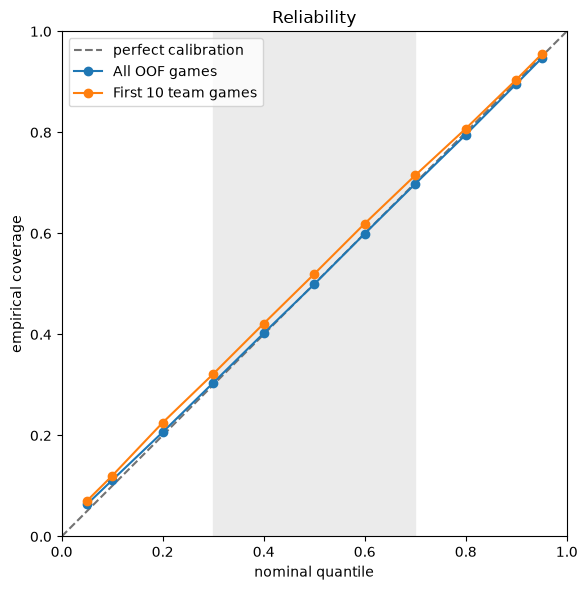

In [15]:
plot_reliability(
    {
        "All OOF games": table_all,
        "First 10 team games": table_early,
    }
)
plt.show()

Same jittered hits, drawn with ML-insights. Each trained quantile is its own bin. The bars are 95% binomial intervals around the empirical rate, and the histogram is how many games sit in that bin. The logit scale stretches the 0.05 and 0.95 tails. Change `knot_bins` when a bin is too thin or too wide.


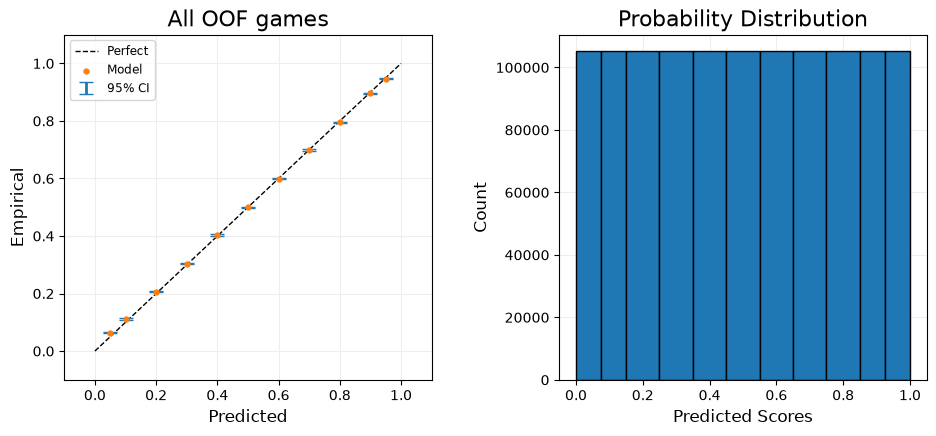

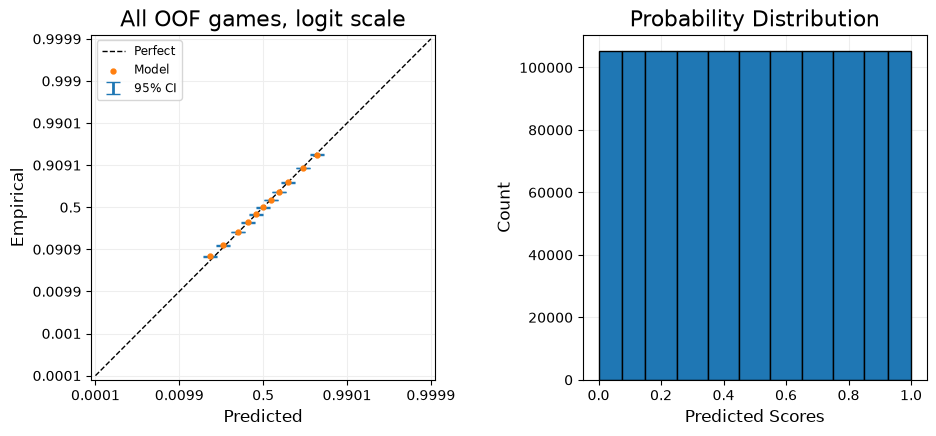

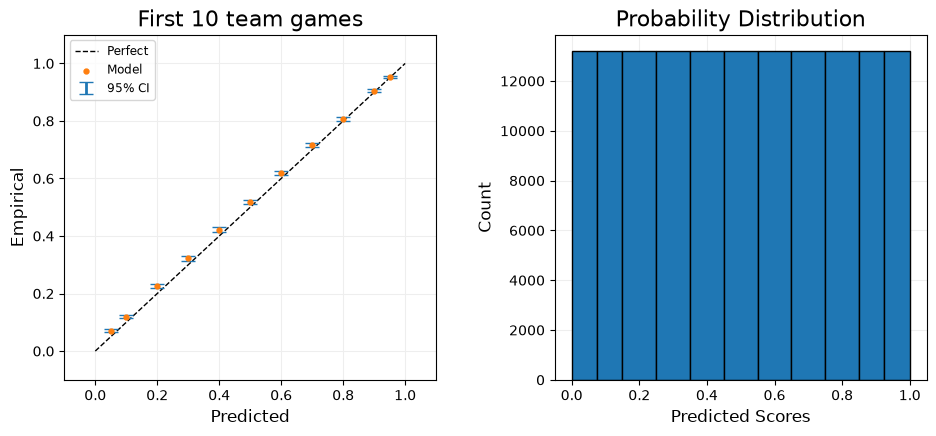

In [16]:
knot_bins = quantile_reliability_bins(taus)
y_rel, p_rel = reliability_pairs(y_oof, Q, taus, np.random.default_rng(SEED))
y_early, p_early = reliability_pairs(
    y_oof[early], Q[early], taus, np.random.default_rng(SEED)
)


def _reliability_diagram(outcomes, predicted, title, *, scaling="none"):
    plt.figure(figsize=(10, 5))
    ml.plot_reliability_diagram(
        outcomes,
        predicted,
        bins=knot_bins,
        show_histogram=True,
        error_bars=True,
        ci_ref="point",
        scaling=scaling,
        reliability_title=title,
    )
    plt.show()


_reliability_diagram(y_rel, p_rel, "All OOF games")
_reliability_diagram(y_rel, p_rel, "All OOF games, logit scale", scaling="logit")
_reliability_diagram(y_early, p_early, "First 10 team games")


In [17]:
print(
    "Selection metric is mean pinball across the grid: "
    f"all OOF games {table_all['pinball'].mean():.3f}, "
    f"first 10 team games {table_early['pinball'].mean():.3f}."
)
wf_pinball, wf_coverage = score_predictions(
    y_val_last, preds_last, last_fold["fold"]
)
display(wf_pinball.round(4))
display(wf_coverage.round(4))


Selection metric is mean pinball across the grid: all OOF games 1.514, first 10 team games 1.490.


,split,quantile,pinball
0,2019-20..2024-25 -> 2025-26,0.05,0.4564
1,2019-20..2024-25 -> 2025-26,0.10,0.8241
2,2019-20..2024-25 -> 2025-26,0.20,1.4064
3,2019-20..2024-25 -> 2025-26,0.30,1.8230
4,2019-20..2024-25 -> 2025-26,0.40,2.0936
5,2019-20..2024-25 -> 2025-26,0.50,2.2243
6,2019-20..2024-25 -> 2025-26,0.60,2.2158
7,2019-20..2024-25 -> 2025-26,0.70,2.0528
8,2019-20..2024-25 -> 2025-26,0.80,1.7112
9,2019-20..2024-25 -> 2025-26,0.90,1.1246


,split,interval,coverage,target
0,2019-20..2024-25 -> 2025-26,80%,0.8094,0.8
1,2019-20..2024-25 -> 2025-26,90%,0.9067,0.9


In [18]:
holdout = evaluate_holdout(
    ppm_df,
    ppm_holdout,
    features=PTS_FEATURES,
    target_col=TARGET_COL,
    xgb_params=XGB_PARAMS,
    role_col=ROLE_COL,
    tiers=POINT_TIERS,
    wf_results=wf_results,
    quantiles=QUANTILES,
    fold_label=f"{HOLDOUT_SEASON} Blind Holdout",
)
models_ho = holdout["models_ho"]
preds_ho = holdout["preds_ho"]
ho_metrics = holdout["ho_metrics"]
X_ho = holdout["X_ho"]
y_ho = holdout["y_ho"]

ho_pinball, ho_coverage = score_predictions(
    y_ho, preds_ho, f"{HOLDOUT_SEASON} holdout"
)
display(ho_pinball.round(4))
display(ho_coverage.round(4))


── 2026-27 Blind Holdout ─────────────────────────────────────────────────
  Round count from the last 10% of regular-season training dates; refit on the full window; predict holdout (never in eval_set).
  Non-regular rows excluded from the stopping tail: 0

2026-27 Blind Holdout
  n= 2413
  pinball  | q0.05=0.432  q0.10=0.783  q0.20=1.355  q0.30=1.774  q0.40=2.061  q0.50=2.212  q0.60=2.199  q0.70=2.042  q0.80=1.715  q0.90=1.134  q0.95=0.690
  mean pinball | 1.491
  coverage | 80%=80.8% (target 80%)  90%=91.3% (target 90%)
  Starters   | n= 1070 | pinball q50: 2.714 | 80% coverage: 79.6%
  Bench      | n= 1343 | pinball q50: 1.812 | 80% coverage: 81.8%
  minute tiers by predicted q50
  <8         | n= 1091 | pinball q50: 1.629 | 80% coverage: 83.0%
  8-15       | n=  800 | pinball q50: 2.418 | 80% coverage: 79.1%
  15-25      | n=  455 | pinball q50: 3.052 | 80% coverage: 78.7%
  25+        | n=   67 | pinball q50: 3.539 | 80% coverage: 79.1%

2026-27 Blind Holdout | first 10 team game

,split,quantile,pinball
0,2026-27 holdout,0.05,0.4316
1,2026-27 holdout,0.10,0.7829
2,2026-27 holdout,0.20,1.3546
3,2026-27 holdout,0.30,1.7742
4,2026-27 holdout,0.40,2.0614
5,2026-27 holdout,0.50,2.2119
6,2026-27 holdout,0.60,2.1993
7,2026-27 holdout,0.70,2.0419
8,2026-27 holdout,0.80,1.7147
9,2026-27 holdout,0.90,1.1343


,split,interval,coverage,target
0,2026-27 holdout,80%,0.8081,0.8
1,2026-27 holdout,90%,0.9126,0.9


### Holdout, once

Run this after the early-season coverage gap for tau between 0.3 and 0.7 is inside about ±2.5 percentage points. Early stopping chooses the round count on the latest regular-season dates, then refits on the full train window. The PIT map is the one fit on every out-of-fold row above. Do not iterate on this cell.


In [19]:
# Holdout, raw knots beside PIT-recalibrated knots.
# R is fit on the walk-forward rows, which include 2025-26.
# Dates on or after 2026-10-20 stay out. Calibrated is cold-start fallback,
# then the quantile grid of R(F), then a clip to [0, 100].

oof = wf["oof"].copy()
knots = [f"q_{level:.2f}" for level in QUANTILES]
base_oof, group_oof = fold_base_knots(
    oof, ppm_df, [result["train_mask"] for result in wf_results],
    spec=POINTS_SPEC,
)
taus = np.asarray(QUANTILES, dtype=float)
Q_oof = np.sort(base_oof[knots].to_numpy(dtype=float), axis=1)
y_oof = oof[TARGET_COL].to_numpy(dtype=float)
pit_map = fit_randomized_pit_map(
    y_oof,
    Q_oof,
    taus,
    np.random.default_rng(SEED).random(len(y_oof)),
    oof["game_date"],
)
oof_cal = pd.DataFrame(
    np.clip(
        calibrated_quantile_grid(Q_oof, taus, pit_map),
        POINTS_SPEC.clip_low,
        POINTS_SPEC.clip_high,
    ),
    index=base_oof.index,
    columns=knots,
)
role_quantiles = holdout_role_quantiles(ppm_df, spec=POINTS_SPEC)
base_ho = base_knots(
    preds_ho,
    ppm_holdout["starting"],
    ppm_holdout[LAG_COL],
    role_quantiles=role_quantiles,
    target_col=TARGET_COL,
)
Q_ho = np.sort(base_ho[knots].to_numpy(dtype=float), axis=1)
adjusted = calibrated_quantile_grid(Q_ho, taus, pit_map)
reorder = float(np.mean(np.any(np.diff(adjusted, axis=1) < 0, axis=1)))
preds_ho_cal = pd.DataFrame(
    np.clip(adjusted, POINTS_SPEC.clip_low, POINTS_SPEC.clip_high),
    index=base_ho.index,
    columns=knots,
)
calibration = pit_recalibration_payload(
    pit_map,
    taus,
    oof["game_date"],
    target=TARGET_COL,
    clip_low=POINTS_SPEC.clip_low,
    clip_high=POINTS_SPEC.clip_high,
)
calibration["role_quantiles"] = role_quantiles
calibration["lag_col"] = LAG_COL
print("OOF calibration rows", calibration["date_start"], "→", calibration["date_end"])
display(pd.Series(pit_map.predict(taus), index=taus, name="R(tau)").round(3))

raw_map = {key: np.asarray(preds_ho[key], dtype=float) for key in knots}
cal_map = {key: preds_ho_cal[key].to_numpy(dtype=float) for key in knots}
base_map = {key: base_ho[key].to_numpy(dtype=float) for key in knots}


OOF calibration rows 2022-10-18 → 2026-04-12


0.05    0.041
0.10    0.138
0.20    0.248
0.30    0.346
0.40    0.443
0.50    0.539
0.60    0.634
0.70    0.728
0.80    0.819
0.90    0.911
0.95    1.000
Name: R(tau), dtype: float64

In [20]:
raw_cross, raw_n, _pairs = quantile_crossing(raw_map)
cal_cross, _, _pairs = quantile_crossing(cal_map)
print(
    f"Crossing rows: raw {raw_cross}/{raw_n} ({raw_cross / raw_n:.2%}), "
    f"calibrated {cal_cross}/{raw_n} ({cal_cross / raw_n:.2%}). "
    f"Recalibrated grid out of order before the clip: {reorder:.2%}."
)


Crossing rows: raw 60/2413 (2.49%), calibrated 0/2413 (0.00%). Recalibrated grid out of order before the clip: 0.00%.


In [21]:
calibration_side = pd.concat(
    [
        quantile_calibration(y_ho, raw_map).assign(version="raw"),
        quantile_calibration(y_ho, cal_map).assign(version="calibrated"),
    ],
    ignore_index=True,
)
print("Holdout calibration. delta = P(y ≤ q) − τ")
display(
    calibration_side.pivot(index="quantile", columns="version", values="delta").round(4)
)

tiers = pd.concat(
    [
        predicted_rate_tiers(y_ho, raw_map, POINT_TIERS).assign(version="raw"),
        predicted_rate_tiers(y_ho, cal_map, POINT_TIERS).assign(version="calibrated"),
    ],
    ignore_index=True,
)
print("Predicted points tiers")
display(tiers.round(4))

point_table = pd.DataFrame(
    [
        holdout_point_distribution("raw", y_ho, raw_map),
        holdout_point_distribution("calibrated", y_ho, cal_map),
    ]
)
tail_table = pd.DataFrame(
    tail_calibration_rows("raw", y_ho, raw_map)
    + tail_calibration_rows("calibrated", y_ho, cal_map)
)
sharp = pd.concat(
    [
        interval_sharpness(y_ho, raw_map).assign(version="raw"),
        interval_sharpness(y_ho, cal_map).assign(version="calibrated"),
    ],
    ignore_index=True,
)
print("q50 RMSE and 11-knot CRPS. CRPS is twice the mean pinball at the trained knots.")
display(point_table.round(4))
print("Tail calibration. delta = empirical − nominal")
display(tail_table.round(4))
print("Interval sharpness")
display(sharp.round(4))

# Starter, bench, and calendar slices are scored once, under Slice Analysis.
lag = ppm_holdout[LAG_COL].to_numpy(dtype=float)
no_prior = ~np.isfinite(lag)
cold_start = pd.DataFrame(
    [
        {**slice_score("No prior game", no_prior, y_ho, raw_map), "version": "raw"},
        {
            **slice_score("No prior game", no_prior, y_ho, cal_map),
            "version": "calibrated",
        },
        {
            **slice_score("No prior game", no_prior, y_ho, base_map),
            "version": "base fallback",
        },
    ]
)
print("Cold-start slice")
display(cold_start.round(4))


Holdout calibration. delta = P(y ≤ q) − τ


version,calibrated,raw
quantile,,
0.05,0.0930,-0.0052
0.10,0.0571,0.0086
0.20,0.0209,0.0350
0.30,0.0129,0.0473
0.40,0.0211,0.0559
0.50,0.0205,0.0495
0.60,0.0138,0.0386
0.70,0.0182,0.0397
0.80,0.0247,0.0338


Predicted points tiers


,tier,n,share,pinball_q50,empirical_q50,coverage_80,coverage_90,mean_width_80,mean_width_90,version
0,<8,1091,0.4521,1.6289,0.5610,0.8304,0.9368,11.0550,14.1180,raw
1,8-15,800,0.3315,2.4181,0.5525,0.7912,0.9038,15.7139,19.9997,raw
2,15-25,455,0.1886,3.0520,0.5055,0.7868,0.8747,18.8062,24.2526,raw
3,25+,67,0.0278,3.5389,0.6269,0.7910,0.8806,20.9436,26.8938,raw
4,<8,1167,0.4836,1.6607,0.5364,0.8586,0.9272,11.3307,14.1897,calibrated
5,8-15,768,0.3183,2.4142,0.5195,0.8125,0.8958,16.3621,19.9163,calibrated
6,15-25,428,0.1774,3.1441,0.4673,0.8061,0.8668,19.8056,24.0302,calibrated
7,25+,50,0.0207,3.4782,0.6200,0.8000,0.8600,22.1225,26.5088,calibrated


q50 RMSE and 11-knot CRPS. CRPS is twice the mean pinball at the trained knots.


,model,rmse,crps
0,raw,5.8050,2.9813
1,calibrated,5.8181,2.9697


... (2 outputs left out)

Interval sharpness


,interval,coverage,target,mean_width,median_width,version
0,80%,0.8081,0.8,14.3358,14.5367,raw
1,90%,0.9126,0.9,18.3337,18.4683,raw
2,80%,0.8334,0.8,14.6589,14.8201,calibrated
3,90%,0.9051,0.9,18.0131,18.0624,calibrated


Cold-start slice


,slice,n,mae,bias,p_actual_le_q50,cov_80,mean_width_80,wis,version
0,No prior game,53,2.8057,1.0602,0.5472,0.9245,9.5876,1.9035,raw
1,No prior game,53,3.6879,-1.7384,0.7736,0.9623,14.7228,2.4446,calibrated
2,No prior game,53,3.9245,-2.1887,0.7925,0.9623,15.0189,2.6168,base fallback


In [22]:
dates = pd.to_datetime(ppm_holdout["game_date"])
pin_ci = paired_date_bootstrap(
    row_pinball(y_ho, raw_map["q_0.50"]),
    row_pinball(y_ho, cal_map["q_0.50"]),
    dates,
    n_boot=N_BOOT,
    seed=SEED,
)
wis_ci = paired_date_bootstrap(
    wis_values(y_ho, raw_map),
    wis_values(y_ho, cal_map),
    dates,
    n_boot=N_BOOT,
    seed=SEED,
)
actual = np.asarray(y_ho, dtype=float)
in_raw = ((actual >= raw_map["q_0.10"]) & (actual <= raw_map["q_0.90"])).astype(float)
in_cal = ((actual >= cal_map["q_0.10"]) & (actual <= cal_map["q_0.90"])).astype(float)
cov_ci = paired_date_bootstrap(in_raw, in_cal, dates, n_boot=N_BOOT, seed=SEED)
print(
    "Date-clustered 95% CI, calibrated − raw. "
    f"q50 pinball {pin_ci['diff']:+.4f} "
    f"[{pin_ci['ci_low']:+.4f}, {pin_ci['ci_high']:+.4f}]. "
    f"WIS {wis_ci['diff']:+.4f} "
    f"[{wis_ci['ci_low']:+.4f}, {wis_ci['ci_high']:+.4f}]. "
    f"80% coverage {cov_ci['diff']:+.4f} "
    f"[{cov_ci['ci_low']:+.4f}, {cov_ci['ci_high']:+.4f}]."
)

print("\nTail miss rates on the next fold. The PIT map is fit on earlier folds only.")
miss_rows = []
fold_ids = oof["fold_id"].to_numpy()
for k in np.unique(fold_ids)[1:]:
    past = fold_ids < k
    test = fold_ids == k
    pit_map_k = fit_randomized_pit_map(
        y_oof[past],
        Q_oof[past],
        taus,
        np.random.default_rng(SEED).random(int(past.sum())),
        oof["game_date"].to_numpy()[past],
    )
    test_cal = pd.DataFrame(
        calibrated_quantile_grid(Q_oof[test], taus, pit_map_k),
        index=base_oof.index[test],
        columns=knots,
    )
    raw_lower, raw_upper = tail_miss_rates(
        oof.loc[test, TARGET_COL],
        base_oof.loc[test, "q_0.05"],
        base_oof.loc[test, "q_0.95"],
    )
    cal_lower, cal_upper = tail_miss_rates(
        oof.loc[test, TARGET_COL],
        test_cal["q_0.05"],
        test_cal["q_0.95"],
    )
    miss_rows.append(
        {
            "fold": k,
            "raw_lower": raw_lower,
            "raw_upper": raw_upper,
            "cal_lower": cal_lower,
            "cal_upper": cal_upper,
            "raw_in_band": within_miss_rate_band(raw_lower, raw_upper),
            "cal_in_band": within_miss_rate_band(cal_lower, cal_upper),
        }
    )
display(pd.DataFrame(miss_rows).round(4))


Date-clustered 95% CI, calibrated − raw. q50 pinball -0.0106 [-0.0243, +0.0048]. WIS -0.0116 [-0.0266, +0.0068]. 80% coverage +0.0253 [+0.0166, +0.0348].

Tail miss rates on the next fold. The PIT map is fit on earlier folds only.


,fold,raw_lower,raw_upper,cal_lower,cal_upper,raw_in_band,cal_in_band
0,2,0.0401,0.0502,0.0415,0.0543,True,True
1,3,0.0373,0.0530,0.0385,0.0584,False,False
2,4,0.0382,0.0548,0.0397,0.0599,False,False


In [23]:
tail_frame = calibrated_tail_frame(oof, oof_cal, spec=POINTS_SPEC)
tail_tables = build_tail_tables(
    tail_frame,
    folds=[1, 2, 3, 4],
    fold_ranges=wf["fold_ranges"],
    holdout_start="2026-10-20",
    cap=POINTS_SPEC.clip_high,
)


In [24]:
calibration_raw = quantile_calibration(y_ho, preds_ho)
display(calibration_raw.round(4))
n_crossed, n_rows, crossing_pairs = quantile_crossing(preds_ho)
print(f"Crossing rows: {n_crossed}/{n_rows}")
display(crossing_pairs.round(4))
display(predicted_rate_tiers(y_ho, preds_ho, POINT_TIERS).round(4))
display(interval_sharpness(y_ho, preds_ho).round(4))


,quantile,target,empirical,delta
0,0.05,0.05,0.0448,-0.0052
1,0.10,0.10,0.1086,0.0086
2,0.20,0.20,0.2350,0.0350
3,0.30,0.30,0.3473,0.0473
4,0.40,0.40,0.4559,0.0559
5,0.50,0.50,0.5495,0.0495
6,0.60,0.60,0.6386,0.0386
7,0.70,0.70,0.7397,0.0397
8,0.80,0.80,0.8338,0.0338
9,0.90,0.90,0.9167,0.0167


Crossing rows: 60/2413


,lower,upper,crossing_rate
0,q_0.05,q_0.10,0.0033
1,q_0.10,q_0.20,0.0133
2,q_0.20,q_0.30,0.0066
3,q_0.30,q_0.40,0.0033
4,q_0.40,q_0.50,0.0008
5,q_0.50,q_0.60,0.0008
6,q_0.60,q_0.70,0.0000
7,q_0.70,q_0.80,0.0008
8,q_0.80,q_0.90,0.0000
9,q_0.90,q_0.95,0.0000


,tier,n,share,pinball_q50,empirical_q50,coverage_80,coverage_90,mean_width_80,mean_width_90
0,<8,1091,0.4521,1.6289,0.5610,0.8304,0.9368,11.0550,14.1180
1,8-15,800,0.3315,2.4181,0.5525,0.7912,0.9038,15.7139,19.9997
2,15-25,455,0.1886,3.0520,0.5055,0.7868,0.8747,18.8062,24.2526
3,25+,67,0.0278,3.5389,0.6269,0.7910,0.8806,20.9436,26.8938


,interval,coverage,target,mean_width,median_width
0,80%,0.8081,0.8,14.3358,14.5367
1,90%,0.9126,0.9,18.3337,18.4683


### Baseline


In [25]:
report = compare_to_baselines(
    y_ho,
    preds_ho,
    ppm_holdout,
    ppm_df,
    wf_results,
    target_col=TARGET_COL,
    tiers=POINT_TIERS,
    baseline_cols={
        "Last game": "pts_lag_1",
        "Season-to-date": "season_pts_mean",
        "Last-10 median": "pts_median_10",
    },
    error_cutoffs=(5, 10, 15),
    error_unit="points",
    n_boot=N_BOOT,
    seed=SEED,
)
print(
    f"Identical holdout rows: {report['paired_n']:,} | "
    f"dropped {report['dropped_n']:,}"
)
display(report["point_table"].round(4))
display(report["delta_table"].round(4))
display(report["fold_table"].round(4))
display(report["distribution"].round(4))
display(report["calibration"].round(4))
display(report["subgroup_table"].round(3))
display(report["tail_table"].round(4))
for line in report["checks"]:
    print(line)


Identical holdout rows: 1,965 | dropped 448


,model,mae,median_ae,mean_bias
0,Last game,5.8000,4.0000,0.1064
1,Season-to-date,4.9098,3.7500,0.3461
2,Last-10 median,4.9631,4.0000,-0.3789
3,Quantile XGBoost q50,4.4576,3.4555,-0.1120


,comparison,delta_mae,ci_low,ci_high
0,XGBoost q50 − Last game,-1.3424,-1.4713,-1.2154
1,XGBoost q50 − Season-to-date,-0.4522,-0.7203,-0.2416
2,XGBoost q50 − Last-10 median,-0.5055,-0.6034,-0.4159


,fold,n,model_mae,last_game,season_to_date,last_10_median,best_baseline,model_minus_best
0,2019-20..2021-22 -> 2022-23,25892,4.5001,5.9872,4.7003,4.7858,4.7003,-0.2002
1,2019-20..2022-23 -> 2023-24,26393,4.4073,5.8435,4.6167,4.6789,4.6167,-0.2094
2,2019-20..2023-24 -> 2024-25,26302,4.4623,5.9350,4.6830,4.7672,4.6830,-0.2208
3,2019-20..2024-25 -> 2025-26,26648,4.4485,5.9503,4.6778,4.7371,4.6778,-0.2293


,model,cov_80,width_80_mean,width_80_median,cov_90,width_90_mean,width_90_median,wis,quantile_crossing
0,Quantile XGBoost,0.8081,14.3358,14.5367,0.9126,18.3337,18.4683,2.9813,0.0249


,model,quantile,expected,observed,difference
0,Quantile XGBoost,q05,0.05,0.0448,-0.0052
1,Quantile XGBoost,q10,0.10,0.1086,0.0086
2,Quantile XGBoost,q20,0.20,0.2350,0.0350
3,Quantile XGBoost,q30,0.30,0.3473,0.0473
4,Quantile XGBoost,q40,0.40,0.4559,0.0559
5,Quantile XGBoost,q50,0.50,0.5495,0.0495
6,Quantile XGBoost,q60,0.60,0.6386,0.0386
7,Quantile XGBoost,q70,0.70,0.7397,0.0397
8,Quantile XGBoost,q80,0.80,0.8338,0.0338
9,Quantile XGBoost,q90,0.90,0.9167,0.0167


,model,group,n,mae,bias,wis,cov_80,width_80_mean,width_80_median,cov_90,width_90_mean,width_90_median
0,Quantile XGBoost,Confirmed starter,1070,5.429,-0.074,3.672,0.796,17.134,17.249,0.893,21.961,22.175
1,Quantile XGBoost,Bench,1343,3.623,0.035,2.431,0.818,12.106,12.348,0.929,15.444,15.596
2,Quantile XGBoost,Predicted q50 <8,1091,3.258,0.317,2.193,0.830,11.055,11.264,0.937,14.118,14.285
3,Quantile XGBoost,Predicted q50 8-15,800,4.836,-0.308,3.238,0.791,15.714,15.669,0.904,20.000,19.939
4,Quantile XGBoost,Predicted q50 15-25,455,6.104,-0.071,4.162,0.787,18.806,18.725,0.875,24.253,24.223
5,Quantile XGBoost,Predicted q50 25+,67,7.078,-1.486,4.740,0.791,20.944,20.705,0.881,26.894,26.677
6,Quantile XGBoost,2026-10,1990,4.471,0.004,3.009,0.803,14.312,14.583,0.910,18.301,18.477
7,Quantile XGBoost,2026-11,423,4.201,-0.093,2.849,0.832,14.448,14.333,0.927,18.488,18.384


,model,threshold,rate,n
0,Quantile XGBoost,>5 points,0.3336,805
1,Quantile XGBoost,>10 points,0.0829,200
2,Quantile XGBoost,>15 points,0.0207,50


Quantile XGBoost q50 observed rate 55.0%  (target about 48–52%)
Quantile XGBoost largest |quantile gap| 5.6%
XGBoost q50 vs Season-to-date: delta MAE -0.452 [-0.720, -0.242]
WIS 2.981 (XGBoost) vs best baseline CRPS/MAE 4.910
walk-forward folds with XGBoost MAE below the best baseline: 4 / 4
raw quantile crossing 2.49%


### Features Analysis


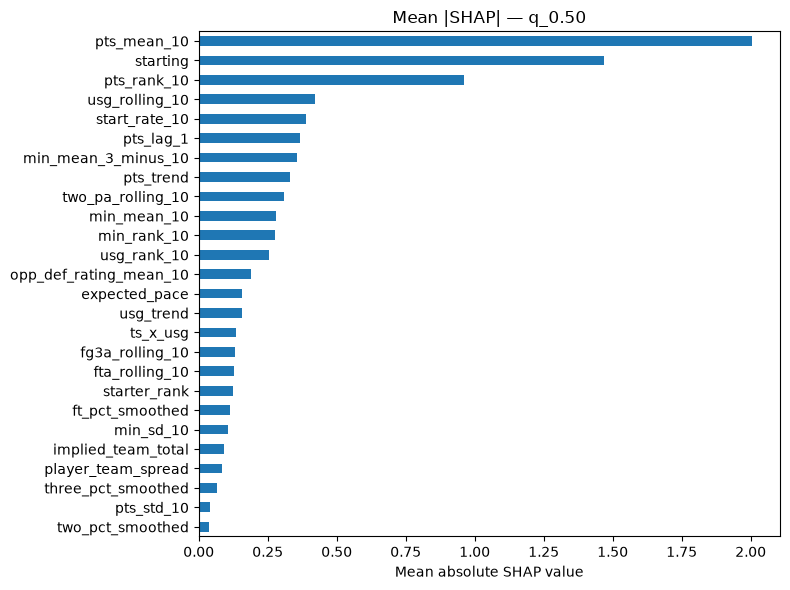

In [26]:
# Live predictions come from the holdout model, trained through the end of
# 2025-26. models_last is the last walk-forward fold; use it only to check
# that importance is stable across folds.
feat_imp = mean_absolute_shap(models_ho["q_0.50"], X_ho)
plot_shap(feat_imp)
plt.show()


In [27]:
pi_df, perm_result = permutation_importance_table(
    models_last["q_0.50"],
    X_val_last,
    y_val_last,
)
print(pi_df.to_string())

                   feature  importance      std  p_value  significant
1              pts_mean_10     0.31842  0.00506      0.0         True
2                 starting     0.19778  0.00519      0.0         True
3              pts_rank_10     0.06460  0.00218      0.0         True
4           usg_rolling_10     0.02953  0.00201      0.0         True
5            start_rate_10     0.02838  0.00195      0.0         True
6                pts_lag_1     0.02246  0.00163      0.0         True
7      min_mean_3_minus_10     0.01956  0.00104      0.0         True
8                pts_trend     0.01605  0.00119      0.0         True
9              min_mean_10     0.01512  0.00114      0.0         True
10       two_pa_rolling_10     0.01250  0.00101      0.0         True
11            starter_rank     0.01124  0.00139      0.0         True
12             min_rank_10     0.00943  0.00105      0.0         True
13             usg_rank_10     0.00866  0.00133      0.0         True
14                ts

In [37]:
train_mask_last = last_fold["train_mask"]
val_mask_last = last_fold["val_mask"]
ablation_df = run_feature_ablation(
    PTS_FEATURES,
    X.loc[train_mask_last],
    ppm_df.loc[train_mask_last, TARGET_COL],
    X.loc[val_mask_last],
    ppm_df.loc[val_mask_last, TARGET_COL],
    xgb_params=XGB_PARAMS,
)


Baseline pinball q50 (all features): 2.2240
                   feature  ablated_pinball  delta_pinball
1                 starting           2.2480         0.0240
2      min_mean_3_minus_10           2.2313         0.0073
3                pts_trend           2.2288         0.0048
4                pts_lag_1           2.2280         0.0040
5   opp_def_rating_mean_10           2.2274         0.0034
6              pts_mean_10           2.2273         0.0032
7       player_team_spread           2.2267         0.0027
8            start_rate_10           2.2266         0.0026
9             starter_rank           2.2266         0.0026
10             usg_rank_10           2.2265         0.0025
11             min_mean_10           2.2265         0.0025
12               min_sd_10           2.2265         0.0025
13         ft_pct_smoothed           2.2264         0.0024
14       two_pa_rolling_10           2.2262         0.0022
15             min_rank_10           2.2259         0.0019
16          

In [38]:
feature_audit = feature_consensus(
    list(X_val_last.columns),
    feat_imp,
    pi_df,
    perm_result.importances,
    ablation_df,
)
print(feature_audit.to_string())


                   feature  mean_abs_shap  shap_rank  perm_rank  perm_importance  perm_importance_std   perm_pvalue  ablation_delta  shap_norm  perm_norm  consensus
1              pts_mean_10       2.005893          1          1          0.31842              0.00506  1.011479e-53          0.0032   1.000000   1.000000   1.000000
2                 starting       1.467343          2          2          0.19778              0.00519  2.047672e-47          0.0240   0.731516   0.621129   0.676323
3              pts_rank_10       0.959819          3          3          0.06460              0.00218  2.917880e-44         -0.0004   0.478499   0.202877   0.340688
4           usg_rolling_10       0.419985          4          4          0.02953              0.00201  2.088008e-35          0.0018   0.209375   0.092739   0.151057
5            start_rate_10       0.387738          5          5          0.02838              0.00195  2.581787e-35          0.0026   0.193299   0.089128   0.141214
6         

### Slice Analysis


In [30]:
dates = pd.to_datetime(ppm_holdout["game_date"])
raw_q = {key: np.asarray(pred, dtype=float) for key, pred in preds_ho.items()}
blocks = regular_season_blocks(dates)
print("April is late regular season, not the postseason")
holdout_season = df.loc[df["season_year"].astype("string").eq(str(HOLDOUT_SEASON))]
print(holdout_season["season_type"].astype("string").value_counts(dropna=False).to_string())
calendar = pd.DataFrame(
    [slice_score(name, mask, y_ho, raw_q) for name, mask in blocks.items()]
)
display(calendar.round(3))

starting = ppm_holdout["starting"].to_numpy()
role = pd.DataFrame(
    [
        slice_score("Confirmed starter", starting == 1, y_ho, raw_q),
        slice_score("Bench", starting == 0, y_ho, raw_q),
    ]
)
display(role.round(3))
for _, row in role.iterrows():
    if row["n"] == 0:
        continue
    print(
        f"  {row['slice']}: bias {row['bias']:+.3f} points, "
        f"P(actual <= q50) {row['p_actual_le_q50']:.1%}. {role_reading(row)}."
    )

preds_ho_mono, shift, before, after = monotone_shift(raw_q)
print(f"Crossing before {before:.2%} of rows; after rearrangement {after:.2%}.")
display(shift.round(4))


April is late regular season, not the postseason
season_type
Regular Season    2413


,slice,n,mae,bias,p_actual_le_q50,cov_80,mean_width_80,wis
0,October–February,0,NaN,NaN,NaN,NaN,NaN,NaN
1,March 1–14,0,NaN,NaN,NaN,NaN,NaN,NaN
2,March 15–31,0,NaN,NaN,NaN,NaN,NaN,NaN
3,April regular season,2413,4.424,-0.013,0.55,0.808,14.336,2.981


,slice,n,mae,bias,p_actual_le_q50,cov_80,mean_width_80,wis
0,Confirmed starter,1070,5.429,-0.074,0.524,0.796,17.134,3.672
1,Bench,1343,3.623,0.035,0.570,0.818,12.106,2.431


  Confirmed starter: bias -0.074 points, P(actual <= q50) 52.4%. q50 is too high: actuals fall under the median more often than 50%.
  Bench: bias +0.035 points, P(actual <= q50) 57.0%. q50 is too high: actuals fall under the median more often than 50%.
Crossing before 2.49% of rows; after rearrangement 0.00%.


,quantile,mean_abs_shift,share_changed
0,q_0.05,0.0009,0.0079
1,q_0.10,0.0012,0.0166
2,q_0.20,0.0016,0.0178
3,q_0.30,0.0011,0.0112
4,q_0.40,0.0004,0.0037
5,q_0.50,0.0001,0.0017
6,q_0.60,0.0000,0.0008
7,q_0.70,0.0001,0.0008
8,q_0.80,0.0001,0.0008
9,q_0.90,0.0000,0.0000


### Error Analysis


In [31]:
prior = ppm_df.loc[
    wf["oof"].index, ["player_id", "game_id", "game_date", TARGET_COL]
].copy()
prior["q50"] = wf["oof"]["q_0.50"].to_numpy()
miss = build_miss_frame(
    df,
    ppm_holdout,
    preds_ho,
    target_col=TARGET_COL,
    lag_col=LAG_COL,
    unit="points",
    history=prior,
)
tracked = miss.loc[miss["residual_count"].ge(10)].copy()
latest = (
    tracked.sort_values(["player_id", "game_date", "game_id"])
    .groupby("player_id", sort=False)
    .tail(1)
)
latest = latest.reindex(
    latest["residual_median_10"].abs().sort_values(ascending=False).index
)
print(
    "Prior residual is actual minus q50. A positive median means the "
    "player has been scoring above the prediction."
)
display(
    latest[
        [
            "player_name",
            "residual_count",
            "residual_median_5",
            "residual_median_10",
            "residual_median_20",
            "residual_mad_10",
            "error",
        ]
    ].head(20)
)
way_off = miss["abs_error"] >= 5
print(
    f"{HOLDOUT_SEASON} holdout: {int(way_off.sum()):,} / {len(miss):,} rows "
    f"missed by 5+ points ({way_off.mean():.1%}). "
    f"Median |error| {miss['abs_error'].median():.1f}."
)
display(
    miss_view(
        miss.nsmallest(20, "error"),
        target_col=TARGET_COL,
        lag_col=LAG_COL,
        season_col="season_pts_mean",
        unit="points",
    )
)
display(
    miss_view(
        miss.nlargest(20, "error"),
        target_col=TARGET_COL,
        lag_col=LAG_COL,
        season_col="season_pts_mean",
        unit="points",
    )
)
biggest = pd.concat(
    [miss.nsmallest(20, "error"), miss.nlargest(20, "error")],
    ignore_index=True,
)
print(biggest["hint"].replace("", "unlabeled").value_counts().to_string())
games = rotation_team_games(miss, rotation_min=8, miss_cutoff=5)
display(games.head(15).round(1))


Prior residual is actual minus q50. A positive median means the player has been scoring above the prediction.


,player_name,residual_count,residual_median_5,residual_median_10,residual_median_20,residual_mad_10,error
2394,Luka Dončić,256,7.913403,8.777366,7.601381,4.551776,10.906574
2374,Scottie Barnes,288,10.004465,8.117017,1.193433,4.538286,-0.054502
2263,Ryan Rollins,161,-8.257755,-5.686511,-0.513755,5.342636,-2.078545
2355,Jalen Green,276,-6.694580,-5.503209,-1.015490,8.212511,-2.560293
2329,Nikola Jokić,288,-6.042028,-5.475019,-3.104443,4.818280,2.780922
2302,Lauri Markkanen,215,-6.079720,-5.271773,-3.672033,1.833484,5.061930
2186,Jaylen Brown,277,-5.744558,-5.181665,-1.479363,2.628639,2.793884
1937,Ousmane Dieng,170,-5.418809,-5.134283,-2.101520,2.439698,-3.545105
1959,Terrence Shannon Jr,81,4.319214,5.127200,2.702269,4.726479,-11.359393
2252,Rudy Gobert,300,-1.660661,-5.059900,-0.366251,2.933570,1.670724


2026-27 holdout: 805 / 2,413 rows missed by 5+ points (33.4%). Median |error| 3.4.


,date,player,game,score,wl,actual,minutes,pred_q50,actual − q50,residual_median_5,residual_median_10,residual_median_20,residual_mad_10,residual_count,q10–q90,fouls,fouls_drawn,starting,+/-,margin,last_game,season_points,pregame_|spread|,ot,hint
1080,2026-10-26,Devin Booker,PHX @ OKC,114-125,L,3,33.8,27.9,-24.9,5.8,4.6,5.7,5.2,262,17–38,3,3,1,-11,-11,43.0,33.0,8.0,False,outside 10–90
1130,2026-10-26,Lauri Markkanen,UTA vs. MEM,105-110,L,2,6.0,23.9,-21.9,-4.0,-1.3,1.1,5.0,213,13–35,0,2,1,2,-5,28.0,20.7,1.5,False,outside 10–90
893,2026-10-25,Scottie Barnes,TOR @ MIN,94-117,L,0,27.9,18.4,-18.4,2.3,-1.1,-1.1,5.7,284,10–28,1,2,1,-27,-23,28.0,25.5,3.5,False,blowout rest
1963,2026-10-31,Stephon Castle,SAS vs. MIN,121-111,W,0,22.2,17.6,-17.6,-3.5,-1.5,0.7,2.8,154,10–27,4,0,1,-2,10,14.0,17.4,12.5,False,outside 10–90
2314,2026-11-02,Victor Wembanyama,SAS vs. UTA,119-97,W,12,24.2,29.4,-17.4,2.2,4.3,1.7,9.0,187,16–39,2,2,1,9,22,43.0,28.0,NaN,False,blowout rest
530,2026-10-23,Jalen Duren,DET @ MIA,128-111,W,4,10.1,20.9,-16.9,-0.1,0.4,1.3,4.5,277,12–31,0,0,1,12,17,22.0,22.0,1.5,False,blowout rest
1133,2026-10-26,Jaren Jackson Jr.,UTA vs. MEM,105-110,L,6,9.7,22.8,-16.8,2.4,2.6,1.4,4.3,254,13–33,1,3,1,-4,-5,20.0,19.7,1.5,False,outside 10–90
1843,2026-10-31,Keyonte George,UTA vs. POR,90-112,L,8,28.7,24.3,-16.3,3.4,3.2,0.9,5.0,201,14–35,3,4,1,-10,-22,31.0,24.4,6.5,False,blowout rest
1821,2026-10-30,Jalen Green,PHX vs. DEN,120-127,L,2,24.5,17.6,-15.6,-5.8,-3.4,-0.4,8.2,275,9–28,0,0,1,-9,-7,20.0,14.0,4.0,False,outside 10–90
1806,2026-10-30,Yaxel Lendeborg,GSW vs. LAL,112-95,W,6,24.2,21.4,-15.4,6.0,NaN,NaN,NaN,5,12–30,6,1,1,-20,17,26.0,22.6,2.5,False,fouled out


,date,player,game,score,wl,actual,minutes,pred_q50,actual − q50,residual_median_5,residual_median_10,residual_median_20,residual_mad_10,residual_count,q10–q90,fouls,fouls_drawn,starting,+/-,margin,last_game,season_points,pregame_|spread|,ot,hint
212,2026-10-21,Ty Jerome,MEM vs. UTA,123-103,W,45,31.7,19.1,25.9,0.8,0.2,1.8,2.1,132,11–29,4,4,1,22,20,17.0,NaN,2.0,False,outside 10–90
996,2026-10-26,Anthony Edwards,MIN @ CLE,125-127,L,47,41.2,23.0,24.0,-1.1,-4.0,1.2,7.4,301,13–36,3,5,1,11,-2,26.0,28.7,3.5,True,overtime
76,2026-10-21,Anthony Edwards,MIN @ MIA,131-106,W,45,32.6,21.9,23.1,-6.9,-3.1,1.6,10.2,298,14–34,1,6,1,25,25,22.0,NaN,1.5,False,outside 10–90
1426,2026-10-28,Stephen Curry,GSW @ MIN,119-114,W,44,31.6,21.9,22.1,0.5,1.0,0.4,1.1,246,13–32,0,11,1,10,5,24.0,23.7,3.5,False,outside 10–90
1702,2026-10-30,Scottie Barnes,TOR vs. ORL,114-121,L,41,38.9,19.3,21.7,8.3,0.9,-0.3,7.4,286,10–28,6,3,1,-11,-7,28.0,19.8,5.5,False,outside 10–90
776,2026-10-24,Jamal Murray,DEN vs. NOP,141-135,W,42,42.9,20.9,21.1,-1.7,-1.2,-0.3,4.8,267,11–32,3,10,1,14,6,6.0,6.0,11.5,True,overtime
0,2026-10-20,Paul George,BOS @ DET,113-121,L,38,30.6,17.2,20.8,-2.5,1.0,0.5,6.0,208,9–27,5,5,1,9,-8,11.0,NaN,1.5,False,outside 10–90
818,2026-10-25,Luka Dončić,LAL @ UTA,132-123,W,52,38.4,31.7,20.3,-2.5,5.3,1.4,6.4,252,21–43,4,9,1,3,9,23.0,25.5,6.5,False,outside 10–90
2048,2026-11-01,Yaxel Lendeborg,GSW vs. LAC,124-112,W,37,33.9,17.5,19.5,6.0,NaN,NaN,NaN,6,10–27,1,5,1,6,12,6.0,19.8,1.5,False,unexpected start
1823,2026-10-30,Christian Braun,DEN @ PHX,127-120,W,31,37.5,12.6,18.4,1.1,0.4,0.2,3.2,285,5–21,1,1,1,9,7,15.0,11.5,4.0,False,outside 10–90


hint
outside 10–90       25
blowout rest         7
fouled out           2
overtime             2
garbage time         2
unexpected bench     1
unexpected start     1


,game_id,game_date,team_abbreviation,matchup,score,wl,n_rotation,n_off_5,mean_abs_error,margin,ot,players_off_by_5
139,0022600135,2026-10-28,PHI,PHI @ IND,114-109,W,7,6,6.1,5.0,False,"Anfernee Simons (27 min, +11.05, 2 PF), LeBron..."
30,0022600021,2026-10-30,DAL,DAL vs. HOU,116-111,W,5,5,10.3,5.0,False,"Kyrie Irving (35 min, +14.34, 3 PF), P.J. Wash..."
99,0022600115,2026-10-25,TOR,TOR @ MIN,94-117,L,6,5,9.2,-23.0,False,"Scottie Barnes (28 min, -18.45, 1 PF), Ja'Kobe..."
76,0022600104,2026-10-24,CHA,CHA vs. MIA,115-110,W,6,5,9.2,5.0,False,"Brandon Miller (36 min, +16.13, 1 PF), Dennis ..."
170,0022600151,2026-10-31,CLE,CLE @ MIL,136-111,W,7,5,8.0,25.0,False,"Donovan Mitchell (24 min, -12.01, 5 PF), Evan ..."
196,0022600164,2026-11-02,DAL,DAL vs. SAC,100-115,L,7,5,7.6,-15.0,False,"Cooper Flagg (40 min, -10.79, 2 PF), Max Chris..."
177,0022600154,2026-11-01,ORL,ORL vs. BOS,97-108,L,6,5,7.1,-11.0,False,"Tristan da Silva (35 min, +13.33, 2 PF), Antho..."
154,0022600143,2026-10-28,LAC,LAC vs. LAL,87-103,L,6,5,7.1,-16.0,False,"Keaton Wagler (28 min, +9.52, 5 PF), Brook Lop..."
28,0022600020,2026-10-30,IND,IND @ MIA,125-145,L,7,5,6.9,-20.0,False,"Quenton Jackson (24 min, +15.22, 2 PF), Pascal..."
101,0022600116,2026-10-25,OKC,OKC vs. LAC,108-101,W,6,5,6.9,7.0,False,"Jalen Williams (32 min, -10.06, 3 PF), Shai Gi..."


### Save Exploratory Artifact


In [32]:
metadata = exploratory_metadata(
    ppm_df,
    ppm_holdout,
    ho_metrics,
    wf_results,
    features=PTS_FEATURES,
    label=TARGET_COL,
    label_rule="pts, minutes > 0",
)
display(metadata)


{'created_at': '2026-11-04T05:26:53.979007+00:00',
 'status': 'exploratory',
 'model_name': 'quantile_xgboost',
 'artifact_stem': 'pts_nba_model',
 'features': ['pts_mean_10',
  'pts_std_10',
  'pts_lag_1',
  'pts_trend',
  'pts_rank_10',
  'two_pa_rolling_10',
  'two_pct_smoothed',
  'fg3a_rolling_10',
  'three_pct_smoothed',
  'fta_rolling_10',
  'ft_pct_smoothed',
  'min_mean_10',
  'min_mean_3_minus_10',
  'min_rank_10',
  'min_sd_10',
  'ts_x_usg',
  'usg_rolling_10',
  'usg_trend',
  'usg_rank_10',
  'starting',
  'starter_rank',
  'start_rate_10',
  'opp_def_rating_mean_10',
  'expected_pace',
  'implied_team_total',
  'player_team_spread'],
 'label': 'pts',
 'label_rule': 'pts, minutes > 0',
 'quantiles': [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95],
 'point_forecast': 0.5,
 'interval': [0.1, 0.9],
 'params': {'objective': 'reg:quantileerror',
  'n_estimators': 1651,
  'max_depth': 5,
  'learning_rate': 0.05146292410167199,
  'subsample': 0.7518573938647881,
  'col

In [33]:
save_path = save_model_bundle(
    models_ho,
    train_df=ppm_df,
    holdout_df=ppm_holdout,
    wf_results=wf_results,
    ho_metrics=ho_metrics,
    features=PTS_FEATURES,
    artifact_stem=ARTIFACT_STEM,
    metadata=metadata,
    calibration=calibration,
)
bundle = load_model_bundle(save_path)
assert list(X_ho.columns) == list(bundle["feature_names"])
scores = loaded_holdout_scores(bundle["quantile_models"], X_ho, y_ho)
print("Saved quantiles:", ", ".join(scores["quantiles"]))
print(f"Loaded model pinball q50 (holdout): {scores['pinball_q50']:.3f}")
print(f"Loaded model 80% coverage (holdout): {scores['coverage_80']:.1%}")
print(f"Trained on data up to      : {bundle['train_end'].date()}")
print(f"Holdout through            : {bundle['val_end'].date()}")


Saved to /Users/alexgonzalez/Documents/nba_quant/models/saved_models/pts_nba_model_2026-11-02.joblib
Loaded /Users/alexgonzalez/Documents/nba_quant/models/saved_models/pts_nba_model_2026-11-02.joblib
Saved quantiles: q_0.05, q_0.10, q_0.20, q_0.30, q_0.40, q_0.50, q_0.60, q_0.70, q_0.80, q_0.90, q_0.95
Loaded model pinball q50 (holdout): 2.212
Loaded model 80% coverage (holdout): 80.8%
Trained on data up to      : 2026-04-12
Holdout through            : 2026-11-02


In [34]:
tail_path = save_path.with_name(
    save_path.name.replace("_model_", "_tails_cal_")
)
save_tail_sidecar(tail_tables, tail_path)
print(f"Wrote calibrated tail tables to {tail_path.relative_to(ROOT)}")


Wrote calibrated tail tables to models/saved_models/pts_nba_tails_cal_2026-10-26.joblib


In [35]:
predictions = build_oos_predictions(
    wf, ppm_df, ppm_holdout, preds_ho, oof_cal=oof_cal, preds_ho_cal=preds_ho_cal
)
path = write_oos_predictions(predictions, ROOT / "data/oos/nba/pts_predictions.parquet")
print(f"Wrote {len(predictions):,} rows to {path.relative_to(ROOT)}")
cal_cols = [column for column in predictions.columns if column.startswith("cal_q_")]
print(f"Calibrated knot columns: {len(cal_cols)}")
predictions.groupby("window_id").agg(
    rows=("game_id", "size"),
    first=("game_date", "min"),
    last=("game_date", "max"),
)


Wrote 107,648 rows to data/oos/nba/pts_predictions.parquet
Calibrated knot columns: 11


,rows,first,last
window_id,,,
-1,2413,2026-10-20,2026-11-02
1,25892,2022-10-18,2023-04-09
2,26393,2023-10-24,2024-04-14
3,26302,2024-10-22,2025-04-13
4,26648,2025-10-21,2026-04-12


### Conclusion
